# Medical Cost Prediction — Practice

**Task:** Predict `charges`, a continuous target in US dollars, using the six attributes in `insurance.csv`.

Dataset: [Medical Cost Personal Datasets on Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance). Column definitions are in `data_dictionary.csv`.

Complete the empty code cells and add your written analysis. The practice notebook contains no solution code or results. Open `medical_cost_solution.ipynb` when you want a reference.

Treat this as a take-home regression project. Explain your decisions, compare the required model families, diagnose errors and support your conclusion with measured results.


## 1. Objective and evaluation

Define the prediction unit, target and intended use. Choose primary and secondary regression metrics and explain their differences. State how you will reserve the final test data. Decide how to compare a log-target model with models fitted directly in dollars.

## 2. Setup

Import the libraries, set a random seed and locate the CSV with relative paths. Create an output folder for figures and tables. Use the supplied requirements if needed. Keep fitting calls explicit and use small search parameter lists.

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## 3. Load and inspect the data

Load the CSV. Inspect shape, schema, sample rows, missing values and duplicate records. Check repeated predictor profiles, including profiles with different charges. Decide how to prevent repeated profiles from crossing partitions. Preserve the downloaded CSV.

In [148]:
raw = pd.read_csv("insurance.csv")

print(raw.duplicated().sum())
print(raw.isnull().sum())

print((raw["charges"] > 0).all())

raw.head()


1
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
True


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [149]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [150]:
print(raw["smoker"].value_counts())
print(raw["region"].value_counts())
print(raw["sex"].value_counts())




smoker
no     1064
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64
sex
male      676
female    662
Name: count, dtype: int64


## 4. Train, validation and test split

Create reproducible train, validation and test partitions, keeping identical predictor profiles together. Build three CV folds inside training. Verify disjoint groups, full row coverage and that each training row appears in exactly one held-out CV fold. Use training data for EDA.

## 5. Exploratory data analysis

Using training data, plot the target and log-target distributions, correlations, charges against age/BMI, and charges by smoker status and region. Show subgroup counts. Explain skewness, large observations and any plausible interactions without making causal claims.

In [151]:
df=raw.drop_duplicates()

df["smoker"] = df["smoker"].str.lower().map({"yes": 1, "no": 0})

df=pd.get_dummies(df, columns=["smoker", "region", "sex"], drop_first=True, dtype=int)

df["charges"] = df.pop("charges")

df["charges"] = np.log1p(df["charges"])

df.head()




,age,bmi,children,smoker_1,region_northwest,region_southeast,region_southwest,sex_male,charges
0,19,27.900,0,1,0,0,1,0,9.734236
1,18,33.770,1,0,0,1,0,1,7.453882
2,28,33.000,3,0,0,1,0,1,8.400763
3,33,22.705,0,0,1,0,0,1,9.998137
4,32,28.880,0,0,1,0,0,1,8.260455


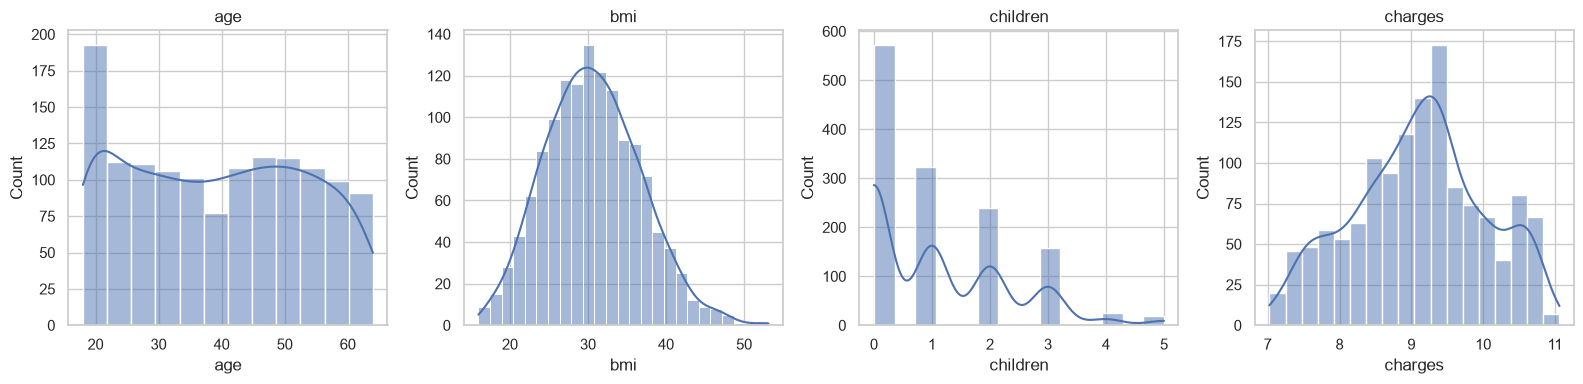

In [152]:
cols = ["age", "bmi", "children", "charges"]

fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 4))
for ax, col in zip(axes, cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

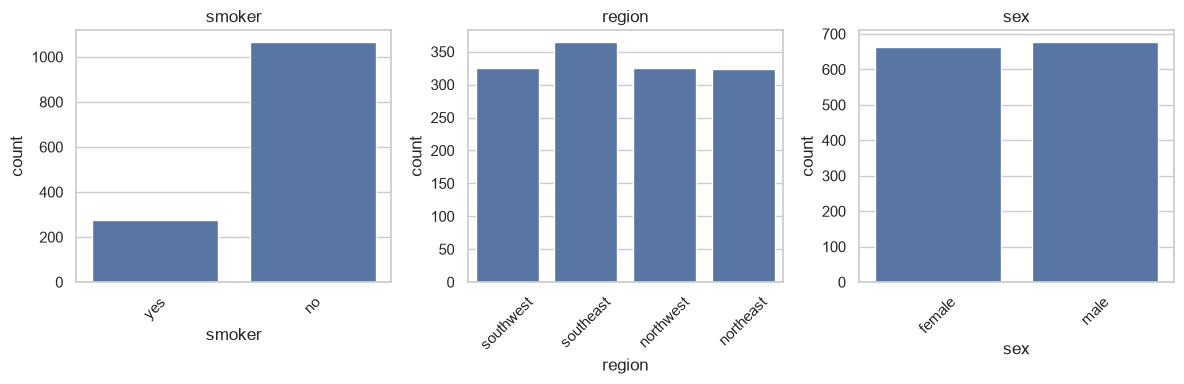

In [153]:
cat_cols = ["smoker", "region", "sex"]

fig, axes = plt.subplots(1, len(cat_cols), figsize=(4 * len(cat_cols), 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(x=raw[col], ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

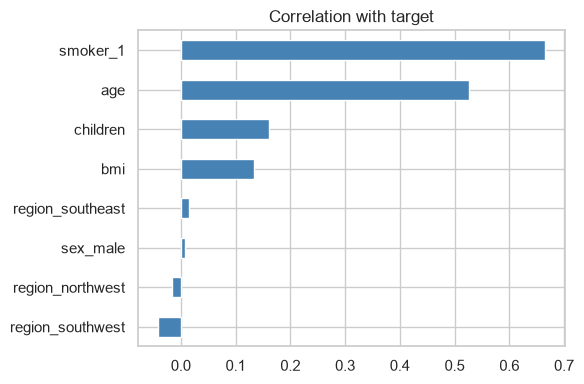

In [154]:
fig, ax = plt.subplots(figsize=(6, 4))

corr = df.corr(numeric_only=True)["charges"].drop("charges")
corr.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Correlation with target")

plt.tight_layout()
plt.show()

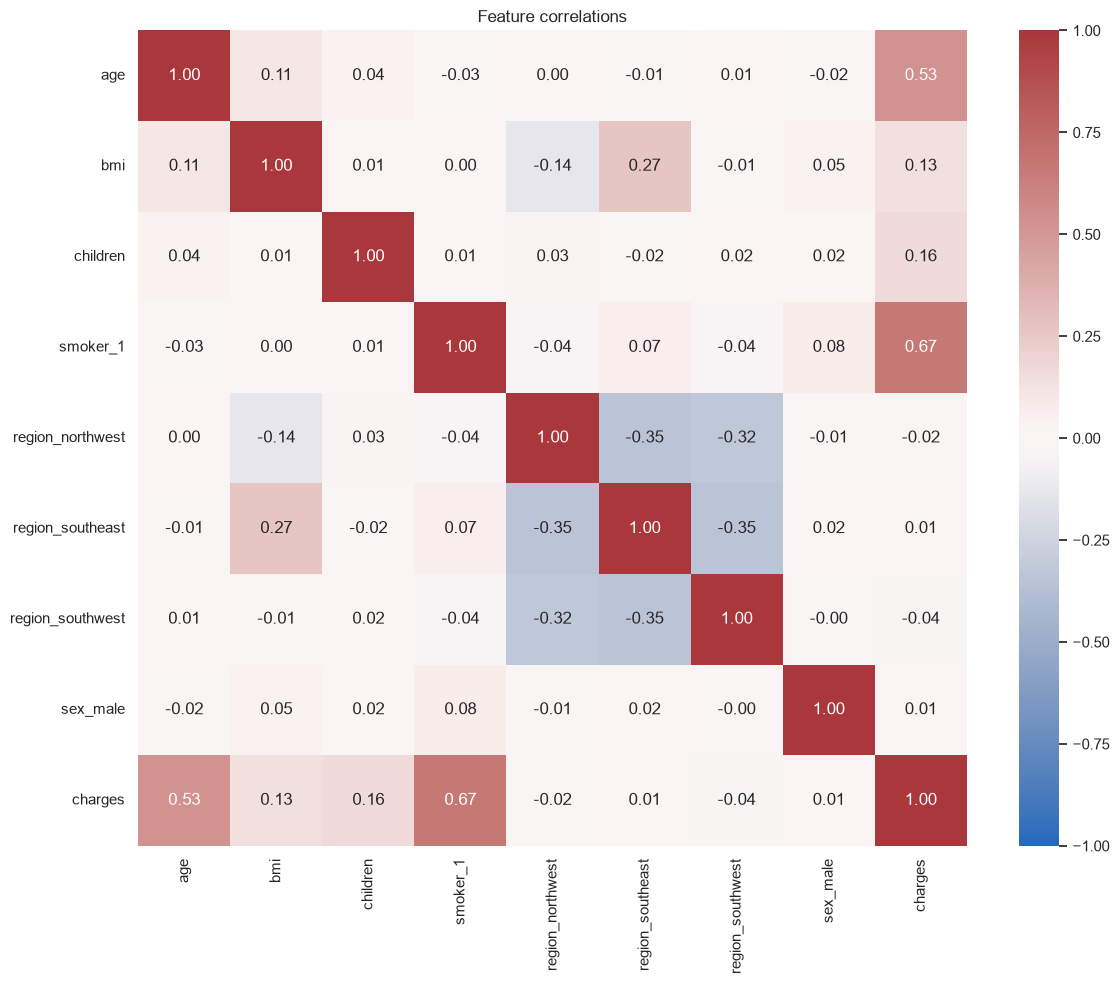

In [155]:
corr_matrix = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    annot=True, fmt=".2f"
)
ax.set_title("Feature correlations")
plt.tight_layout()
plt.show()

## 6. Feature engineering and preprocessing

Propose a few justified nonlinear terms or interactions. Apply deterministic transforms consistently to each partition. Build fold-safe scaled, unscaled and native-category preprocessing with clear column lists. Explain your encoding and why tree models do not need numerical standardization.

In [156]:
X = df.drop(columns=["charges"])
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (1069, 8), Test: (268, 8)


## 7. Baseline and metrics

Fit mean and median dummy regressors. Write a short metric function that returns RMSE, MAE, R² and mean prediction error. Store validation predictions and fitted models for later comparison. Keep fitting outside the metric function.

In [157]:
results = {}  # model_name -> log-scale and dollar-scale RMSE, MAE, R2

def evaluate(name, y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    y_true_dollars = np.expm1(y_true)
    y_pred_dollars = np.expm1(y_pred)
    rmse_dollars = mean_squared_error(y_true_dollars, y_pred_dollars) ** 0.5
    mae_dollars = mean_absolute_error(y_true_dollars, y_pred_dollars)
    r2_dollars = r2_score(y_true_dollars, y_pred_dollars)

    results[name] = {
        "RMSE": rmse, "MAE": mae, "R2": r2,
        "RMSE_dollars": rmse_dollars, "MAE_dollars": mae_dollars, "R2_dollars": r2_dollars,
    }
    print(f"{name:22s}  log     RMSE={rmse:.4f}   MAE={mae:.4f}   R2={r2:.4f}")
    print(f"{'':22s}  dollars RMSE={rmse_dollars:.2f}   MAE={mae_dollars:.2f}   R2={r2_dollars:.4f}")
    return rmse, mae, r2, rmse_dollars, mae_dollars, r2_dollars

## 8. Linear regression

Fit OLS with your scaled and encoded inputs. Evaluate on validation data, export a coefficient plot, and interpret selected coefficients in the presence of interactions and correlated inputs. Explain strengths and weaknesses.

In [158]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LinearRegression", y_test, y_pred_lr)

LinearRegression        log     RMSE=0.3978   MAE=0.2607   R2=0.8295
                        dollars RMSE=7197.03   MAE=3755.92   R2=0.7181


(0.3977747132916927,
 0.2606564515736235,
 0.829478626133356,
 7197.032607369916,
 3755.9245759096716,
 0.7181193522954393)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/3326384596.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


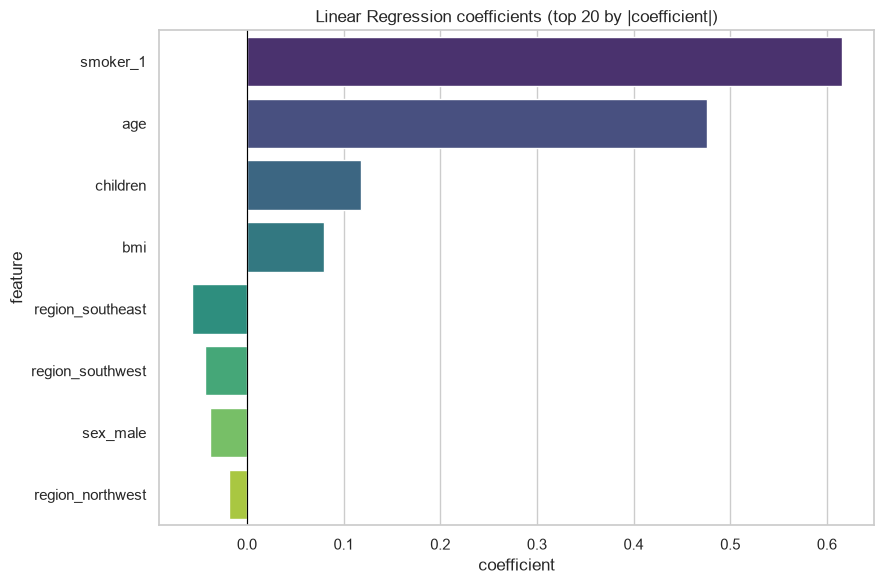

,feature,coefficient
3,smoker_1,0.615148
0,age,0.475584
2,children,0.118389
1,bmi,0.079538
5,region_southeast,-0.056974
6,region_southwest,-0.043708
7,sex_male,-0.038368
4,region_northwest,-0.018823


In [159]:
feat = X_train.columns
coef_df = pd.DataFrame({
    "feature": feat,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Linear Regression coefficients (top 20 by |coefficient|)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df

## 9. Ridge, Lasso and Elastic Net

Fit and tune Ridge, Lasso and Elastic Net using the same CV folds and three strengths per model. Compare validation scores, coefficient magnitudes and sparsity. Explain penalty strength, the L1/L2 difference and correlated-feature behavior.

In [160]:
alphas = np.logspace(-2, 2, 3)

ridge = RidgeCV(alphas=alphas, cv=2)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)
evaluate("Ridge", y_test, y_pred_ridge)
print(f"Chosen alpha: {ridge.alpha_:.4f}")

Ridge                   log     RMSE=0.3978   MAE=0.2607   R2=0.8295
                        dollars RMSE=7196.94   MAE=3755.91   R2=0.7181
Chosen alpha: 0.0100


In [161]:
lasso = LassoCV(alphas=alphas, cv=2, max_iter=5000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)
evaluate("Lasso", y_test, y_pred_lasso)
print(f"Chosen alpha: {lasso.alpha_:.4f}")
print(f"Features zeroed out: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")

Lasso                   log     RMSE=0.4048   MAE=0.2636   R2=0.8234
                        dollars RMSE=7110.58   MAE=3759.71   R2=0.7249
Chosen alpha: 0.0100
Features zeroed out: 1 / 8


In [162]:
elastic = ElasticNetCV(
    alphas=alphas,
    l1_ratio=[.5],
    cv=2,
    max_iter=5000,
    random_state=RANDOM_STATE,
)
elastic.fit(X_train_scaled, y_train)

y_pred_elastic = elastic.predict(X_test_scaled)
evaluate("ElasticNet", y_test, y_pred_elastic)
print(f"Chosen alpha: {elastic.alpha_:.4f}, l1_ratio: {elastic.l1_ratio_:.2f}")
print(f"Features zeroed out: {(elastic.coef_ == 0).sum()} / {len(elastic.coef_)}")

ElasticNet              log     RMSE=0.4021   MAE=0.2629   R2=0.8258
                        dollars RMSE=7105.22   MAE=3746.58   R2=0.7253
Chosen alpha: 0.0100, l1_ratio: 0.50
Features zeroed out: 0 / 8


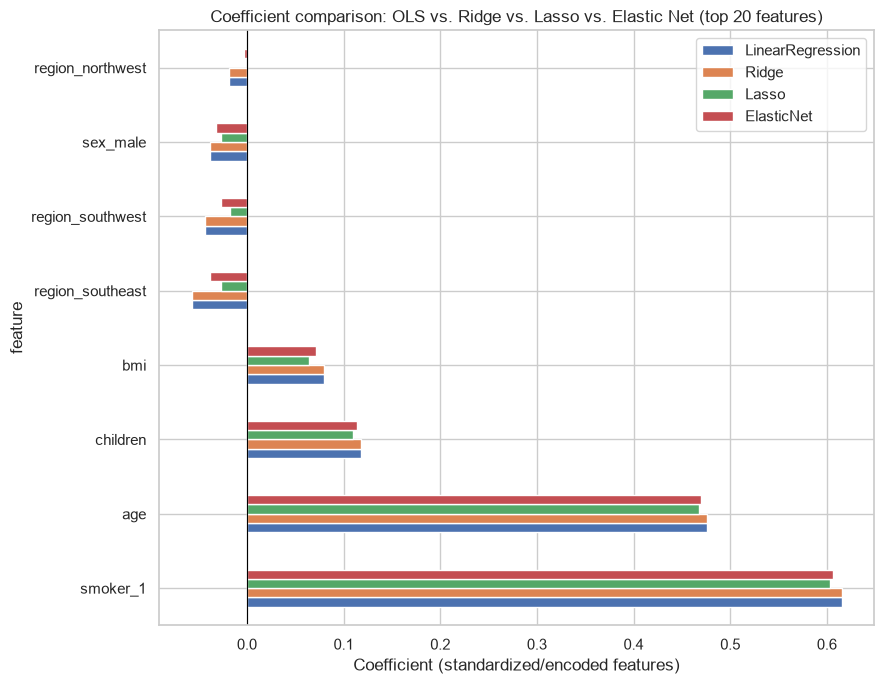

,LinearRegression,Ridge,Lasso,ElasticNet
feature,,,,
smoker_1,0.615148,0.615142,0.603400,0.606298
age,0.475584,0.475580,0.468088,0.469487
children,0.118389,0.118388,0.109456,0.113472
bmi,0.079538,0.079537,0.064045,0.071367
region_southeast,-0.056974,-0.056973,-0.026573,-0.037832
region_southwest,-0.043708,-0.043706,-0.017241,-0.026932
sex_male,-0.038368,-0.038368,-0.026658,-0.032167
region_northwest,-0.018823,-0.018823,-0.000000,-0.002982


In [163]:
coef_compare = pd.DataFrame({
    "feature": feat,
    "LinearRegression": lin_reg.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "ElasticNet": elastic.coef_,
}).set_index("feature")

top_features = coef_compare["LinearRegression"].abs().sort_values(ascending=False).head(20).index
coef_compare.loc[top_features].plot(kind="barh", figsize=(9, 7))
plt.title("Coefficient comparison: OLS vs. Ridge vs. Lasso vs. Elastic Net (top 20 features)")
plt.xlabel("Coefficient (standardized/encoded features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_compare.loc[top_features]

## 10. K-nearest neighbors

Fit KNN with scaled predictors. Explain neighbor count, distance weighting, categorical encoding and prediction cost.

In [164]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
evaluate("KNN", y_test, y_pred_knn)

KNN                     log     RMSE=0.4125   MAE=0.2575   R2=0.8166
                        dollars RMSE=6206.80   MAE=3372.23   R2=0.7904


(0.4124683483720679,
 0.25751711231809987,
 0.8166479645347401,
 6206.799095185872,
 3372.2295064713226,
 0.7903505649784504)

In [165]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV RMSE: {-knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV RMSE: 0.4391


In [166]:
y_pred_knn_tuned = knn_grid.best_estimator_.predict(X_test_scaled)
evaluate("KNN (tuned)", y_test, y_pred_knn_tuned)

KNN (tuned)             log     RMSE=0.4125   MAE=0.2575   R2=0.8166
                        dollars RMSE=6206.80   MAE=3372.23   R2=0.7904


(0.4124683483720679,
 0.25751711231809987,
 0.8166479645347401,
 6206.799095185872,
 3372.2295064713226,
 0.7903505649784504)

## 11. Multilayer perceptron

Fit an MLP with scaled inputs and early stopping. Consider target scaling without leaking validation outcomes into it. Export training loss and the internal validation curve. Compare its behavior with OLS and KNN.

In [167]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
evaluate("MLP", y_test, y_pred_mlp)

MLP                     log     RMSE=0.3641   MAE=0.2255   R2=0.8571
                        dollars RMSE=5447.96   MAE=2959.53   R2=0.8385


(0.3641360472064992,
 0.22553093813356156,
 0.8571001321018834,
 5447.960491174735,
 2959.5329150987527,
 0.8384800323827001)

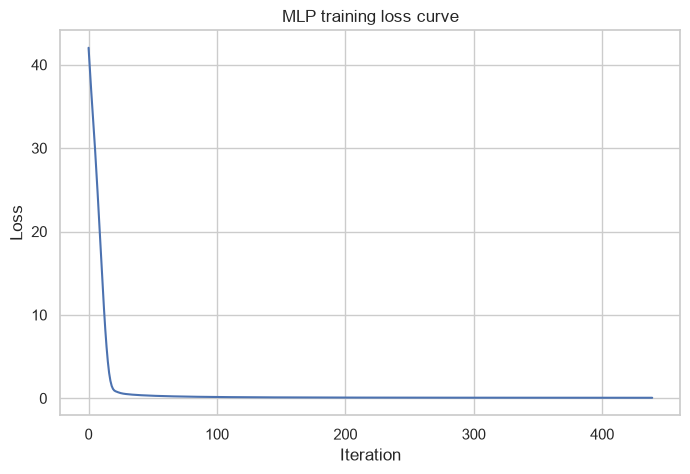

Stopped after 440 iterations (early_stopping=triggered)


In [168]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

print(f"Stopped after {len(mlp.loss_curve_)} iterations "
      f"(early_stopping={'triggered' if mlp.n_iter_ < mlp.max_iter else 'not triggered'})")

In [169]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPRegressor(
        activation="relu",
        learning_rate_init=1e-3,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)

print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV RMSE: {-mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
Best CV RMSE: 0.4490


In [170]:
y_pred_mlp_tuned = mlp_search.best_estimator_.predict(X_test_scaled)
evaluate("MLP (tuned)", y_test, y_pred_mlp_tuned)

MLP (tuned)             log     RMSE=0.3641   MAE=0.2255   R2=0.8571
                        dollars RMSE=5447.96   MAE=2959.53   R2=0.8385


(0.3641360472064992,
 0.22553093813356156,
 0.8571001321018834,
 5447.960491174735,
 2959.5329150987527,
 0.8384800323827001)

## 12. Random Forest

Fit a Random Forest, evaluate on validation data and export feature importance. Explain the role of leaf size, averaging, extrapolation and correlated predictors.

In [171]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
evaluate("RandomForest", y_test, y_pred_rf)

RandomForest            log     RMSE=0.3575   MAE=0.1910   R2=0.8622
                        dollars RMSE=4294.18   MAE=2010.72   R2=0.8996


(0.3575447223125866,
 0.19099964663673977,
 0.862226648279575,
 4294.184115465756,
 2010.7187485415914,
 0.8996494765288721)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/3651918486.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


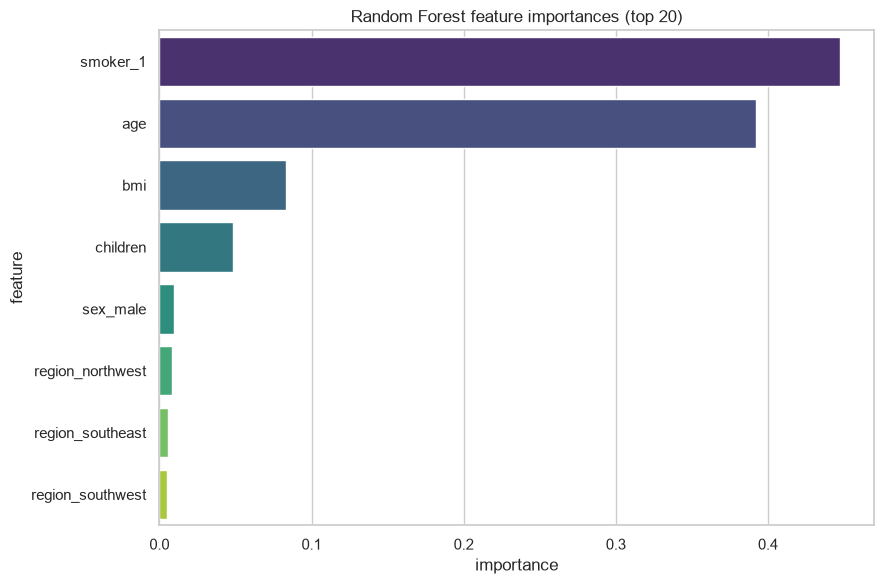

,feature,importance
3,smoker_1,0.447309
0,age,0.392206
1,bmi,0.083175
2,children,0.048524
7,sex_male,0.009776
4,region_northwest,0.008451
5,region_southeast,0.005516
6,region_southwest,0.005041


In [172]:
rf_importance = pd.DataFrame({
    "feature": feat,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances (top 20)")
plt.tight_layout()
plt.show()

rf_importance

In [173]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf_search.fit(X_train_scaled, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.4f}")

Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV RMSE: 0.4003


In [174]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test_scaled)
evaluate("RandomForest (tuned)", y_test, y_pred_rf_tuned)

RandomForest (tuned)    log     RMSE=0.3395   MAE=0.1843   R2=0.8758
                        dollars RMSE=4219.23   MAE=1976.84   R2=0.9031


(0.3394960188876758,
 0.184287361075907,
 0.8757850548197621,
 4219.225924420539,
 1976.8410661698192,
 0.9031222860905382)

## 13. XGBoost

Fit XGBoost, evaluate it and export importance. Explain learning rate, tree count, depth and regularization.

In [175]:
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=2,
)
xgb.fit(
    X_train_scaled, y_train,
    eval_set=[(X_test_scaled, y_test)],
    verbose=False,
)

y_pred_xgb = xgb.predict(X_test_scaled)
evaluate("XGBoost", y_test, y_pred_xgb)


XGBoost                 log     RMSE=0.4012   MAE=0.2263   R2=0.8265
                        dollars RMSE=6910.54   MAE=3073.50   R2=0.7401


(0.40118557305023916,
 0.22627893385935388,
 0.8265416965353531,
 6910.543791628044,
 3073.4966958224913,
 0.7401140705466581)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/4195925514.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


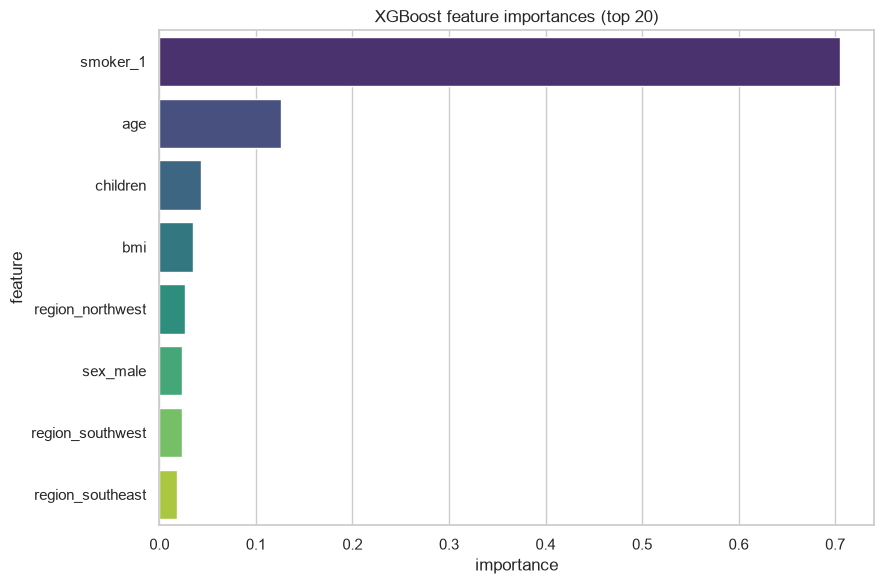

,feature,importance
3,smoker_1,0.704979
0,age,0.125928
2,children,0.042720
1,bmi,0.034661
4,region_northwest,0.026738
7,sex_male,0.023349
6,region_southwest,0.023139
5,region_southeast,0.018486


In [176]:
xgb_importance = pd.DataFrame({
    "feature": feat,
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances (top 20)")
plt.tight_layout()
plt.show()

xgb_importance


In [177]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    param_distributions=xgb_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
xgb_search.fit(X_train_scaled, y_train)

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV RMSE: {-xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03}
Best CV RMSE: 0.4561


## 14. CatBoost

Fit CatBoost with native categorical fields. Use a pipeline for numerical imputation and preserve categorical column names. Compare it with the encoded tree models and export feature importance.

In [178]:
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    use_best_model=True,
)

y_pred_cat = cat.predict(X_test)
evaluate("CatBoost", y_test, y_pred_cat)


CatBoost                log     RMSE=0.3307   MAE=0.1868   R2=0.8821
                        dollars RMSE=4516.51   MAE=2195.63   R2=0.8890


(0.33073134372437385,
 0.18683974142778412,
 0.8821159111724334,
 4516.505046083194,
 2195.625867774756,
 0.8889896889240482)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/3227799930.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


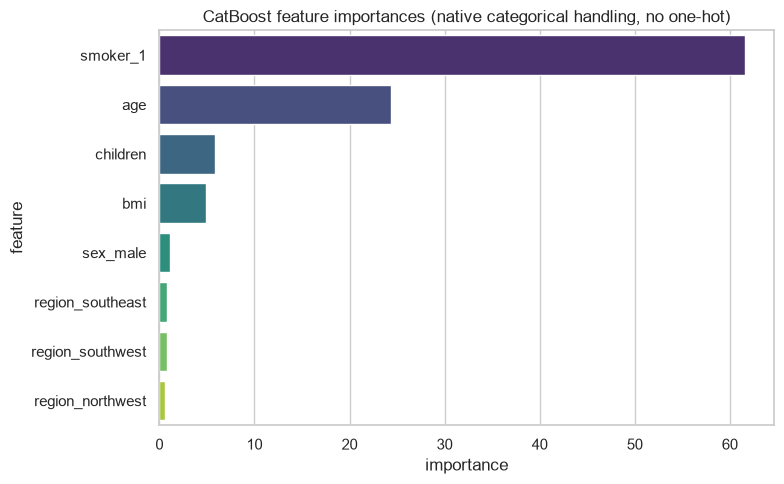

,feature,importance
3,smoker_1,61.560383
0,age,24.351272
2,children,5.896321
1,bmi,4.887474
7,sex_male,1.116161
5,region_southeast,0.786125
6,region_southwest,0.785268
4,region_northwest,0.616995


In [179]:
cat_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": cat.get_feature_importance()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances (native categorical handling, no one-hot)")
plt.tight_layout()
plt.show()

cat_importance


In [180]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostRegressor(
        l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE,
        thread_count=1, allow_writing_files=False,
        verbose=False,
    ),
    param_distributions=cat_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
# cat_features goes to .fit() here, not the constructor above -- CatBoostRegressor's
# sklearn wrapper doesn't round-trip cat_features through get_params()/set_params()
# cleanly, which breaks sklearn's clone() (used internally by RandomizedSearchCV).
# Passing it as a fit param instead sidesteps that entirely.
cat_search.fit(X_train, y_train)

print(f"Best params: {cat_search.best_params_}")
print(f"Best CV RMSE: {-cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 4}
Best CV RMSE: 0.4236


## 15. LightGBM

Fit LightGBM, evaluate it and export importance. Explain leaf growth, minimum leaf size, scaling and small-sample overfitting.

In [181]:
lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=-1,
)
lgbm.fit(
    X_train_scaled, y_train,
    eval_set=[(X_test_scaled, y_test)],
)

y_pred_lgbm = lgbm.predict(X_test_scaled)
evaluate("LightGBM", y_test, y_pred_lgbm)


LightGBM                log     RMSE=0.3850   MAE=0.2330   R2=0.8403
                        dollars RMSE=4736.64   MAE=2640.34   R2=0.8779


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.3849699871900716,
 0.23299360987673995,
 0.8402803957276113,
 4736.641481763717,
 2640.340455792938,
 0.8779045870195242)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/2392704502.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


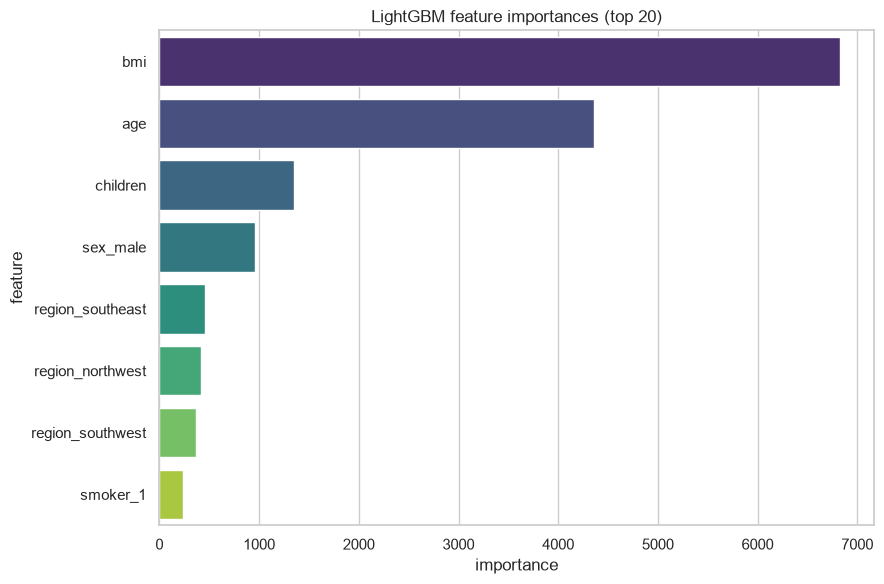

,feature,importance
1,bmi,6826
0,age,4355
2,children,1352
7,sex_male,961
5,region_southeast,456
4,region_northwest,415
6,region_southwest,370
3,smoker_1,241


In [182]:
lgbm_importance = pd.DataFrame({
    "feature": feat,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances (top 20)")
plt.tight_layout()
plt.show()

lgbm_importance


In [183]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        random_state=RANDOM_STATE,
        n_jobs=2,
        verbose=-1,
    ),
    param_distributions=lgbm_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train_scaled, y_train)

print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.4f}")


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV RMSE: 0.4300


## 16. Hyperparameter tuning

Tune KNN, MLP, Random Forest, XGBoost, CatBoost and LightGBM with small explicit parameter lists and two candidates. Keep preprocessing inside the search estimator. Record chosen parameters and training CV mean/variation. Explain why a selected setting may not improve validation error.

## 17. Model comparison

Create the full validation table and a comparison plot using RMSE, MAE and R². Include the dummy baselines, all regularized linear models and both baseline/tuned nonlinear models. Explain substantial differences and small uncertain gaps.

In [184]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df

,RMSE,MAE,R2,RMSE_dollars,MAE_dollars,R2_dollars
CatBoost,0.330731,0.186840,0.882116,4516.505046,2195.625868,0.888990
RandomForest (tuned),0.339496,0.184287,0.875785,4219.225924,1976.841066,0.903122
RandomForest,0.357545,0.191000,0.862227,4294.184115,2010.718749,0.899649
MLP,0.364136,0.225531,0.857100,5447.960491,2959.532915,0.838480
MLP (tuned),0.364136,0.225531,0.857100,5447.960491,2959.532915,0.838480
LightGBM,0.384970,0.232994,0.840280,4736.641482,2640.340456,0.877905
LinearRegression,0.397775,0.260656,0.829479,7197.032607,3755.924576,0.718119
Ridge,0.397776,0.260658,0.829478,7196.939929,3755.908799,0.718127
XGBoost,0.401186,0.226279,0.826542,6910.543792,3073.496696,0.740114
ElasticNet,0.402095,0.262910,0.825755,7105.222034,3746.584050,0.725265


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/3761458768.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/3761458768.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_14580/3761458768.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, met

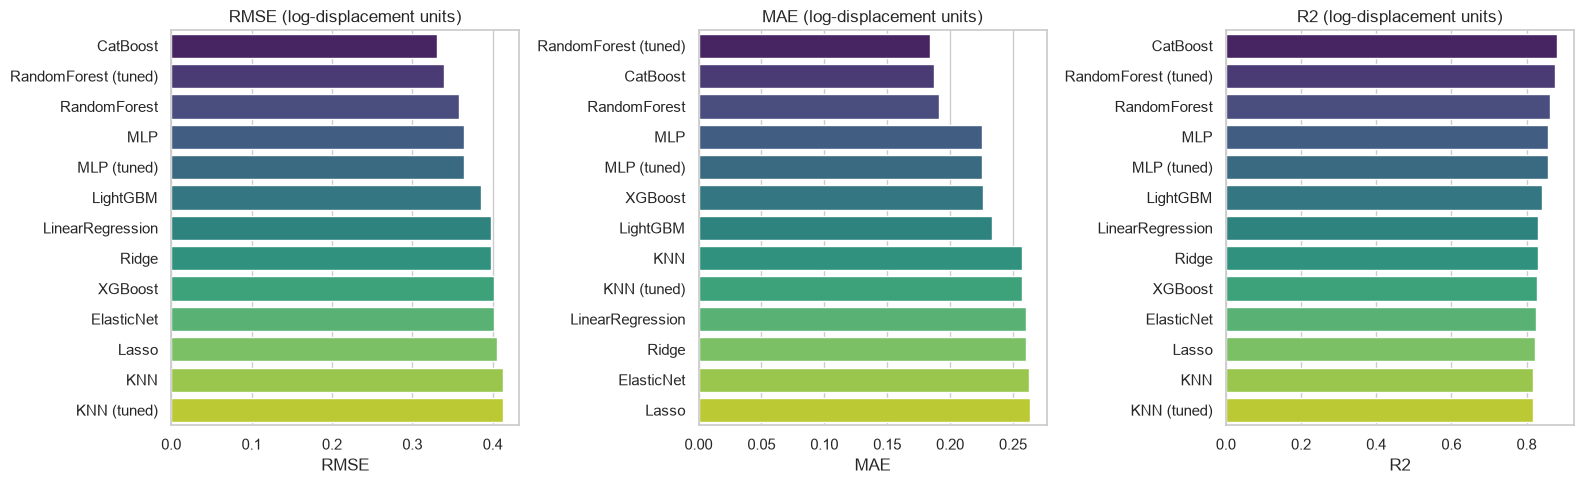

In [185]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2")).index
    sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_title(f"{metric} (log-displacement units)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

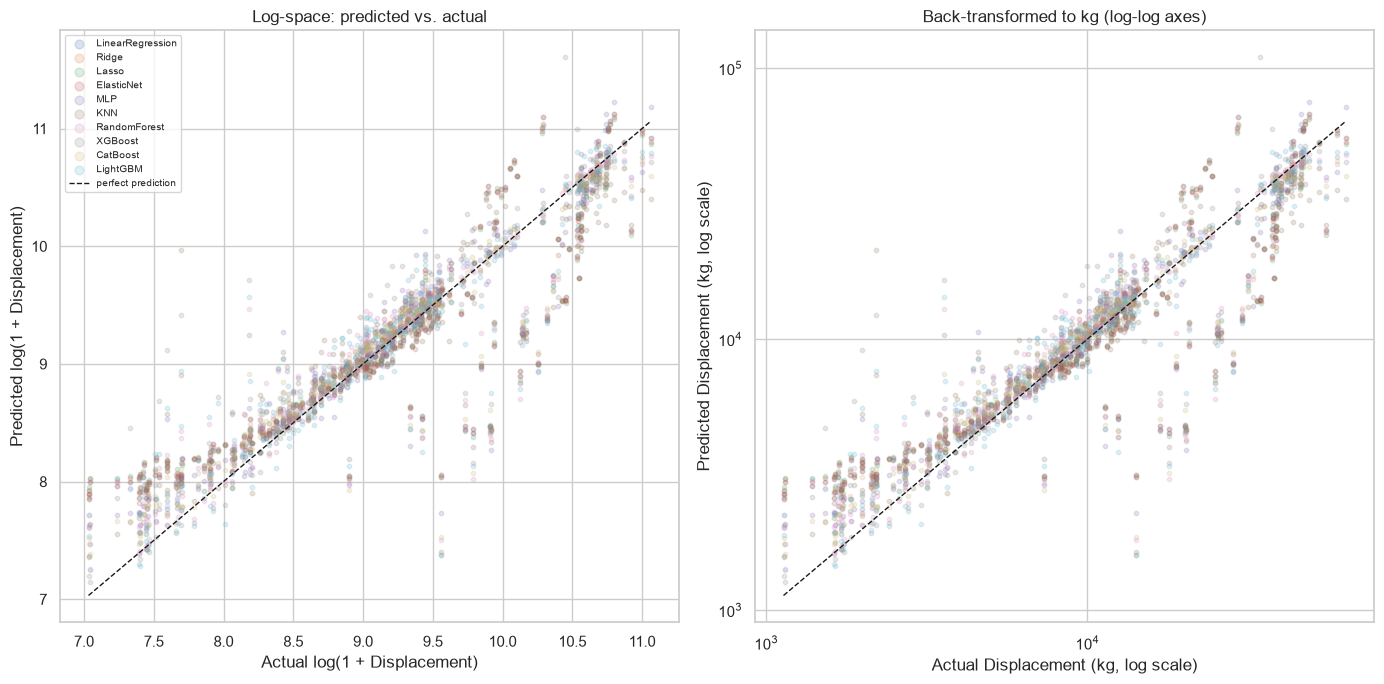

In [186]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

preds = {
    "LinearRegression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic,
    "MLP": y_pred_mlp,
    "KNN": y_pred_knn,
    "RandomForest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred_cat,
    "LightGBM": y_pred_lgbm,
}

ax = axes[0]
for name, p in preds.items():
    ax.scatter(y_test, p, alpha=0.2, s=10, label=name)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "k--", linewidth=1, label="perfect prediction")
ax.set_xlabel("Actual log(1 + Displacement)")
ax.set_ylabel("Predicted log(1 + Displacement)")
ax.set_title("Log-space: predicted vs. actual")
ax.legend(markerscale=2, fontsize=7)

ax = axes[1]
y_test_kg = np.expm1(y_test)
# y_test_kg = y_test
for name, p in preds.items():
    ax.scatter(y_test_kg, np.expm1(p), alpha=0.2, s=10, label=name)
    # ax.scatter(y_test_kg, p, alpha=0.2, s=10, label=name)
lims_kg = [y_test_kg.min(), y_test_kg.max()]
ax.plot(lims_kg, lims_kg, "k--", linewidth=1, label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual Displacement (kg, log scale)")
ax.set_ylabel("Predicted Displacement (kg, log scale)")
ax.set_title("Back-transformed to kg (log-log axes)")

plt.tight_layout()
plt.show()


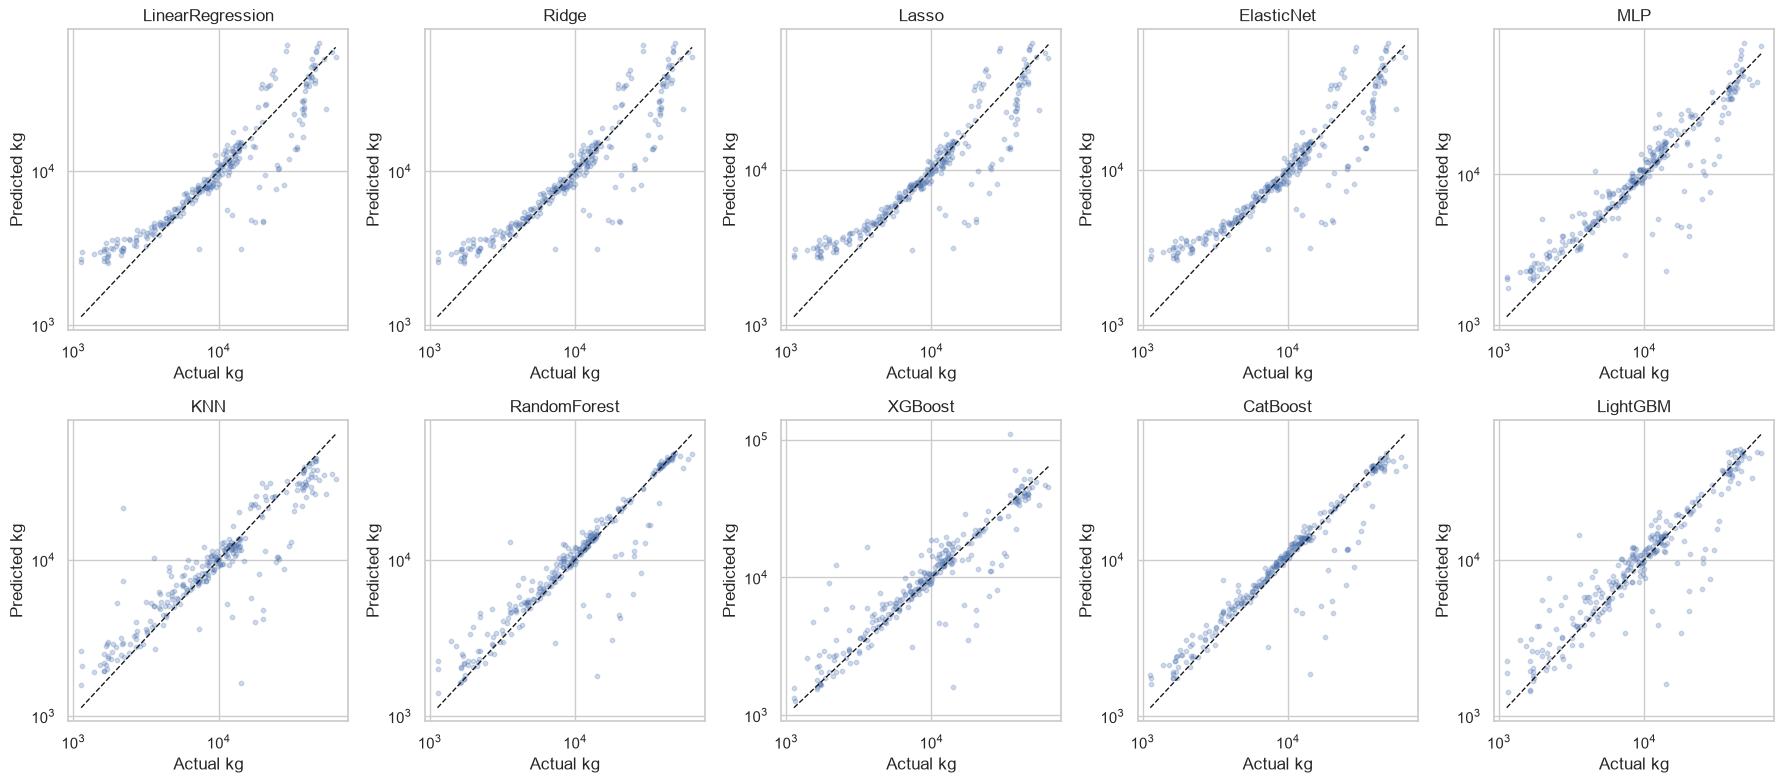

In [187]:
preds = {
    "LinearRegression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic,
    "MLP": y_pred_mlp,
    "KNN": y_pred_knn,
    "RandomForest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred_cat,
    "LightGBM": y_pred_lgbm,
}

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
y_test_kg = np.expm1(y_test)
# y_test_kg = y_test
lims_kg = [y_test_kg.min(), y_test_kg.max()]

for ax, (name, p) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test_kg, np.expm1(p), alpha=0.25, s=10)
    # ax.scatter(y_test_kg, p, alpha=0.25, s=10)
    ax.plot(lims_kg, lims_kg, "k--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Actual kg")
    ax.set_ylabel("Predicted kg")

plt.tight_layout()
plt.show()


## 18. Stacking

Build a stack from three distinct model families. Train its meta-model on out-of-fold predictions, with preprocessing inside each base estimator. Evaluate on validation data and explain its strengths, weaknesses and whether the observed gain justifies its complexity.

In [188]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=Ridge(alpha=1.0),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_pred_stack = stack.predict(X_test_scaled)
evaluate("Stacking", y_test, y_pred_stack)


Stacking                log     RMSE=0.3631   MAE=0.2063   R2=0.8579
                        dollars RMSE=4496.06   MAE=2225.41   R2=0.8900


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.36313153537665793,
 0.20633057007679306,
 0.8578874566010664,
 4496.060595446181,
 2225.411921053052,
 0.8899924147624176)

## 19. Feature ablation and target transformation

Compare the original predictors with your engineered features. Remove a feature and all terms derived from it in an ablation. Fit a log-target alternative and return predictions to dollars. Explain transformation bias and compare all candidates using the same primary metric.

## 20. Final model selection

Choose and record your final model from validation results before accessing test predictions. Refit the selected settings on training plus validation data. If stacking is selected, recreate its internal CV indices for the larger partition. Explain why the final training population differs from the model-comparison population.

## 21. Final test evaluation

Evaluate the locked model and simple references on the final test partition. Report RMSE, MAE, R² and bias in dollars. Plot predictions, residuals and their distribution. Count negative predictions and large errors. Keep model selection unchanged after viewing these results.

## 22. Model interpretation and error analysis

Analyze test errors by meaningful feature groups and target ranges, including counts and bias. Estimate importance by perturbing original fields and consistently rebuilding any derived terms. Explain correlated-feature limitations and why importance is not causal.

## 23. Uncertainty and robustness

Estimate uncertainty for test RMSE and the paired difference against a reference model. Choose a resampling unit consistent with repeated profiles. Explain what the intervals cover and which sources of uncertainty they omit. Suggest a repeated-split or external validation experiment.

## 24. Results and conclusion

Write your conclusion using measured outputs: chosen model, final RMSE and MAE, improvement against references, feature/target-transform findings, strengths and weaknesses, limitations and next experiments. Distinguish prediction from causation and benchmark accuracy from future performance.

## 25. Presentation questions and saved outputs

Prepare answers to likely questions about RMSE versus MAE, outliers, Ridge/Lasso, scaling, interaction interpretation, log-target bias, stacking, leakage, group errors and uncertainty. Save results tables, split identifiers, predictions and plot images with descriptive filenames.